# 01. The problem and the papers' DFO-TR

Phantom 5 (Shepp–Logan) at three settings; the fitness is e1 = ‖ref − W x‖², the squared sinogram error.

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import dfoct
from dfoct import analysis as an

FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
R = an.load()
problems = {(s, a): dfoct.load_problem(p, s, a) for p, s, a in dfoct.SETTINGS}
pd.options.display.float_format = "{:.3g}".format

## The problem

In [3]:
rows = []
for (s, a), p in problems.items():
    rows.append({"setting": an.label(s, a), "unknowns (pixels)": p.D, "measurements (rays)": p.ref.size,
                 "rays per pixel": p.ref.size / p.D})
settings_table = pd.DataFrame(rows).set_index("setting")
an.to_tex(settings_table, FIGURES / "tab_settings.tex")
settings_table

,unknowns (pixels),measurements (rays),rays per pixel
setting,,,
32² / 6 angles,1024,192,0.188
64² / 6 angles,4096,384,0.0938
32² / 32 angles,1024,1024,1


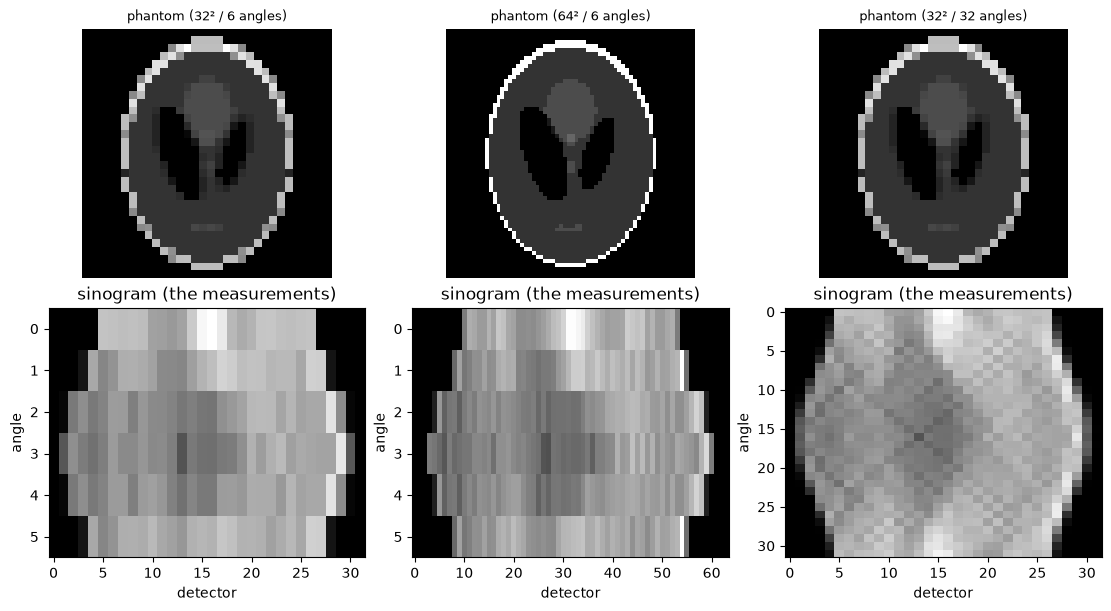

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), layout="constrained")
for k, ((s, a), p) in enumerate(problems.items()):
    an.show(axes[0, k], p.phantom, s, f"phantom ({an.label(s, a)})")
    axes[1, k].imshow(p.ref.reshape(a, s), cmap="gray", aspect="auto", interpolation="nearest")
    axes[1, k].set(title="sinogram (the measurements)", xlabel="detector", ylabel="angle")
fig.savefig(FIGURES / "problem.pdf", bbox_inches="tight")

## DFO-TR, as in the papers' script

Two flies; the best fly *s* stays, the other fly *i* moves every pixel *d*:

$$x_{id} \leftarrow x_{sd} + U(0, \sqrt{3})\,(x_{sd} - x_{id}), \qquad \text{or, with probability } \Delta = 0.001,\; x_{id} \leftarrow U(0, 255)$$

clamped to [0, 255]; one move = one function evaluation (FE).

### A short run of each: the script's method and v1.3 (seed 0, 20k FEs)

In [5]:
from dfoct.paper import PaperDFO

p = problems[(32, 6)]
paper = PaperDFO(5, 32, 6).run(20_000, seed=0)
dfoct.run(p, dfoct.V1_3, 1_000, 0)  # compile first
fast = dfoct.run(p, dfoct.V1_3, 20_000, seed=0)
pd.DataFrame({
    "DFO-TR (paper)": {"FEs": paper.fes, "seconds": paper.seconds, "e1": paper.e1, "PSNR (dB)": dfoct.score(p, paper.x)["psnr"]},
    "v1.3": {"FEs": fast.fes, "seconds": fast.seconds, "e1": fast.e1, "PSNR (dB)": dfoct.score(p, fast.x)["psnr"]},
}).T

,FEs,seconds,e1,PSNR (dB)
DFO-TR (paper),2e+04,1.06,4.07e+05,12.2
v1.3,2e+04,0.00383,4.25e+05,12


## Same search: the papers' DFO-TR and v1.3 at equal FEs (10 seeds)

In [6]:
for fes in (100_000, R["main"].fes.max()):
    display(an.compare(an.at(R["main"], fes), "v1.3", "DFO-TR (paper)").rename_axis(f"PSNR at {fes:,} FEs"))
    display(an.compare(an.at(R["main"], fes), "v1.3", "DFO-TR (paper)", "e1").rename_axis(f"e1 at {fes:,} FEs"))
same = an.compare(an.finals(R["main"]), "v1.3", "DFO-TR (paper)")
an.to_tex(same, FIGURES / "tab_paper_vs_v1_3.tex", digits=3)

,v1.3 median,DFO-TR (paper) median,v1.3 better (pairs),Mann-Whitney p
"PSNR at 100,000 FEs",,,,
32² / 6 angles,12.9,12.8,68%,0.186
64² / 6 angles,11.6,11.6,41%,0.521
32² / 32 angles,18.7,18.4,83%,0.014


,v1.3 median,DFO-TR (paper) median,v1.3 better (pairs),Mann-Whitney p
"e1 at 100,000 FEs",,,,
32² / 6 angles,4.59e+04,4.62e+04,42%,0.571
64² / 6 angles,3.66e+06,3.7e+06,62%,0.385
32² / 32 angles,9.44e+05,1.09e+06,78%,0.0376


,v1.3 median,DFO-TR (paper) median,v1.3 better (pairs),Mann-Whitney p
"PSNR at 1,000,000 FEs",,,,
32² / 6 angles,13.2,13.1,71%,0.121
64² / 6 angles,11.8,11.9,36%,0.307
32² / 32 angles,20.8,20.8,61%,0.427


,v1.3 median,DFO-TR (paper) median,v1.3 better (pairs),Mann-Whitney p
"e1 at 1,000,000 FEs",,,,
32² / 6 angles,3.8e+03,3.72e+03,49%,0.97
64² / 6 angles,6.64e+05,7.08e+05,57%,0.623
32² / 32 angles,2.11e+05,2.18e+05,55%,0.734


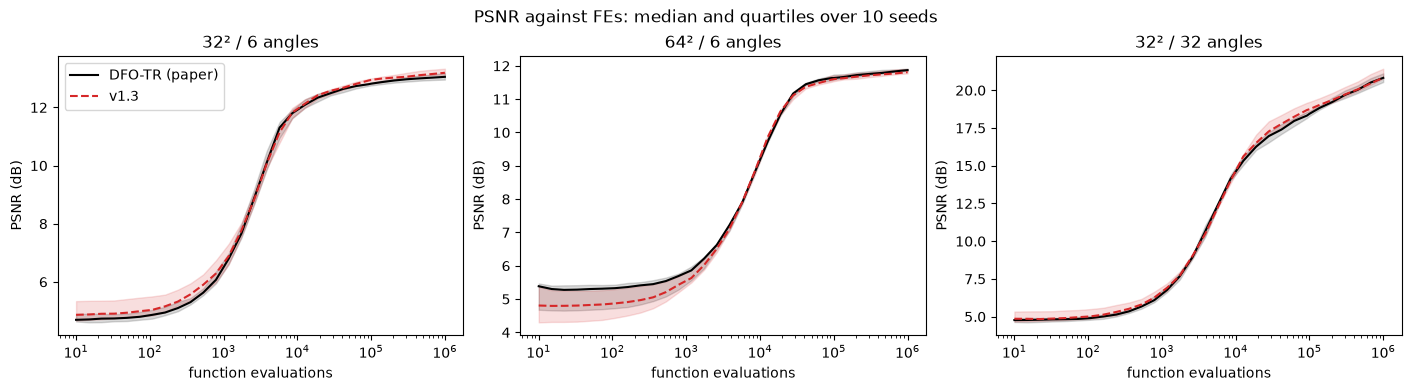

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), layout="constrained")
for ax, (s, a) in zip(axes, an.settings()):
    for m in ("DFO-TR (paper)", "v1.3"):
        sub = R["main"][(R["main"].method == m) & (R["main"]["size"] == s) & (R["main"].alpha == a)]
        q = sub.groupby("fes").psnr.quantile([0.25, 0.5, 0.75]).unstack()
        ax.plot(q.index, q[0.5], color=an.COLORS[m], label=m, ls="--" if m == "v1.3" else "-")
        ax.fill_between(q.index, q[0.25], q[0.75], color=an.COLORS[m], alpha=0.15)
    ax.set(xscale="log", xlabel="function evaluations", ylabel="PSNR (dB)", title=an.label(s, a))
axes[0].legend()
fig.suptitle("PSNR against FEs: median and quartiles over 10 seeds")
fig.savefig(FIGURES / "paper_vs_v1_3.pdf", bbox_inches="tight")

## Faster: time per FE (one thread)

In [8]:
t = R["timing"].pivot_table(index=["size", "alpha"], columns="method", values="us_per_fe")
speed = t.assign(**{f"{m} speed-up": t["DFO-TR (paper)"] / t[m] for m in ("v1.3", "v2.3")})
speed.index = [an.label(s, a) for s, a in speed.index]
speed.columns.name = None
speed.index.name = "setting"
an.to_tex(speed.rename(columns=lambda c: c if "speed-up" in c else f"{c} (µs/FE)"), FIGURES / "tab_timing.tex")
speed.round(3)

,DFO-TR (paper),v1.3,v2.3,v1.3 speed-up,v2.3 speed-up
setting,,,,,
32² / 6 angles,45.2,0.163,0.908,277,49.8
32² / 32 angles,89.9,1.31,5.65,68.8,15.9
64² / 6 angles,108,0.518,4.84,208,22.3


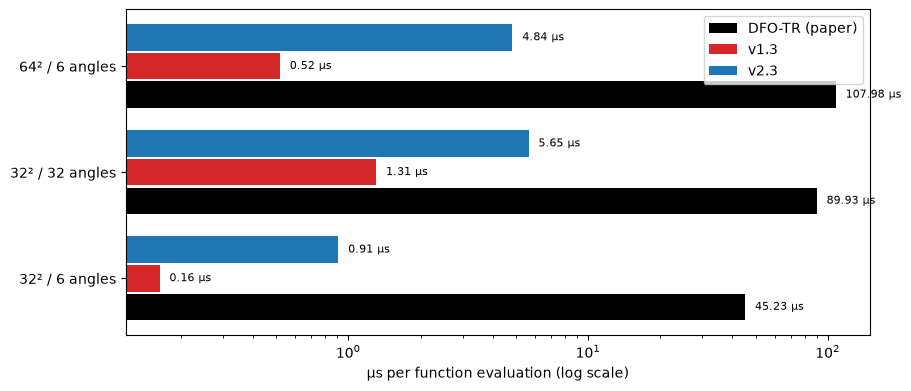

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
methods = ["DFO-TR (paper)", "v1.3", "v2.3"]
for k, m in enumerate(methods):
    y = np.arange(len(t)) + (k - 1) * 0.27
    ax.barh(y, t[m], height=0.25, color=an.COLORS[m], label=m)
    for yy, v in zip(y, t[m]):
        ax.text(v * 1.1, yy, f"{v:.2f} µs", va="center", fontsize=8)
ax.set_yticks(range(len(t)), [an.label(s, a) for s, a in t.index])
ax.set(xscale="log", xlabel="µs per function evaluation (log scale)")
ax.legend(loc="upper right")
fig.savefig(FIGURES / "time_per_fe.pdf", bbox_inches="tight")

## What the papers' DFO-TR reconstructs, next to SIRT-box (1M FEs, median seed)

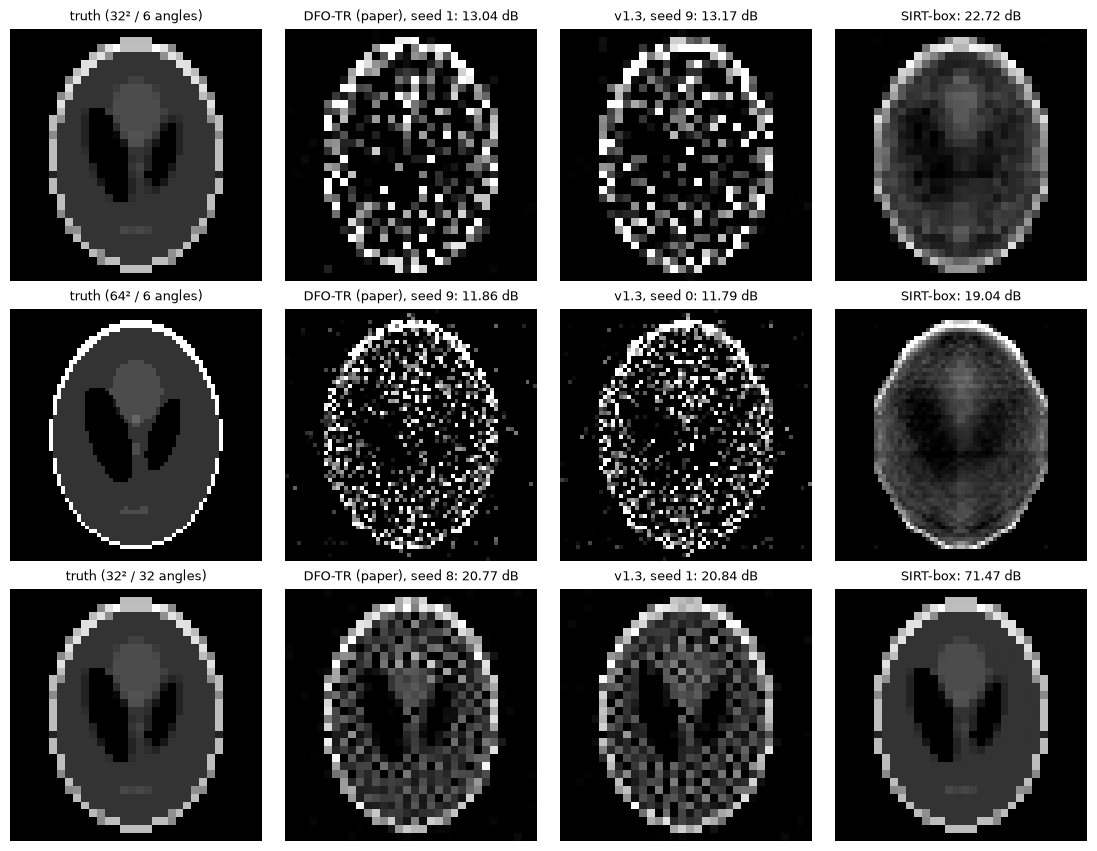

In [10]:
fin = an.finals(R["main"])
fig, axes = plt.subplots(3, 4, figsize=(11, 8.4), layout="constrained")
for row, (s, a) in enumerate(an.settings()):
    p = problems[(s, a)]
    an.show(axes[row, 0], p.phantom, s, f"truth ({an.label(s, a)})")
    for col, m in enumerate(("DFO-TR (paper)", "v1.3"), 1):
        seed = an.median_seed(fin, m, s, a)
        x = R["images"][f"{m}|{s}|{a}|{seed}"]
        an.show(axes[row, col], x, s, f"{m}, seed {seed}: {dfoct.score(p, x)['psnr']:.2f} dB")
    sb = R["sirt"].set_index(["size", "alpha"]).loc[(s, a)]
    an.show(axes[row, 3], R["sirt_images"][f"SIRT-box|{s}|{a}"], s, f"SIRT-box: {sb.psnr:.2f} dB")
fig.savefig(FIGURES / "baseline_images.pdf", bbox_inches="tight")